In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


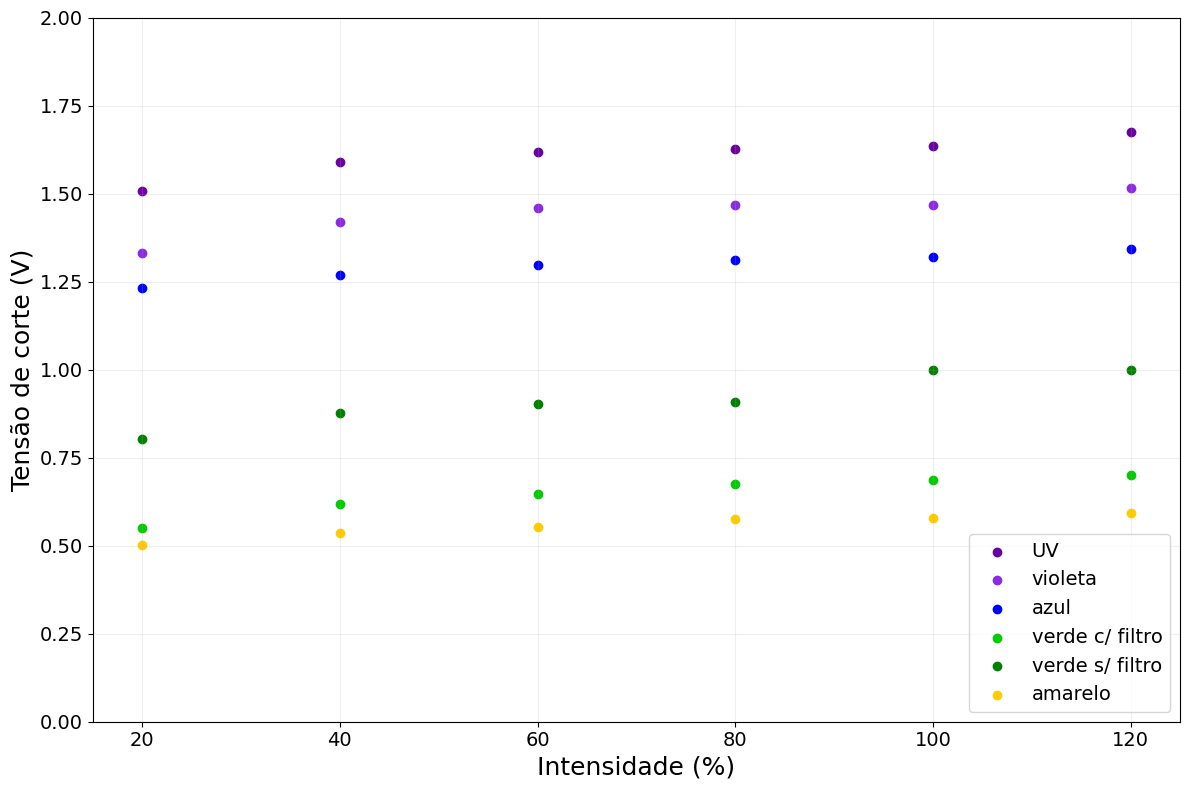

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------
# Função auxiliar para reduzir código repetido
# ---------------------------
def carregar_media(caminho):
    df = pd.read_csv(caminho)
    return df.groupby("opacidade", as_index=False).agg(
        media_tensao=("tensao V", "mean"),
        media_tempo=("tempo s", "mean")
    )
plt.figure(figsize=(12,8))

# ---------------------------
# UV
# ---------------------------
df_UV = carregar_media("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/UV.csv")
plt.scatter(df_UV["opacidade"], df_UV["media_tensao"], color="#6b00a0", label="UV")

# ---------------------------
# Violeta
# ---------------------------
df_violeta = carregar_media("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/violeta.csv")
plt.scatter(df_violeta["opacidade"], df_violeta["media_tensao"], color="#8a2be2", label="violeta")

# ---------------------------
# Azul
# ---------------------------
df_azul = carregar_media("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/azul.csv")
plt.scatter(df_azul["opacidade"], df_azul["media_tensao"], color="#0000ff", label="azul")

# ---------------------------
# Verde com filtro
# ---------------------------
df_verdef = carregar_media("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/verde c  filtro.csv")
plt.scatter(df_verdef["opacidade"], df_verdef["media_tensao"], color="#00cc00", label="verde c/ filtro")

# ---------------------------
# Verde sem filtro (não tem média)
# ---------------------------
df_verde = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/verde s  filtro.csv")
plt.scatter(df_verde["opacidade"], df_verde["tensao V"], color="green", label="verde s/ filtro")

# ---------------------------
# Amarelo com filtro (não tem média)
# ---------------------------
df_amarelof = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/amarelo c  filtro .csv")
plt.scatter(df_amarelof["opacidade"], df_amarelof["tensao V"], color="#ffcc00", label="amarelo")

# ---------------------------
# Gráfico
# ---------------------------
plt.xlabel("Intensidade (%)", fontsize=18)
plt.ylabel("Tensão de corte (V)", fontsize=18)
plt.ylim(0, 2)

plt.grid(alpha=0.2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)

plt.tight_layout()
plt.show()


Mounted at /content/drive


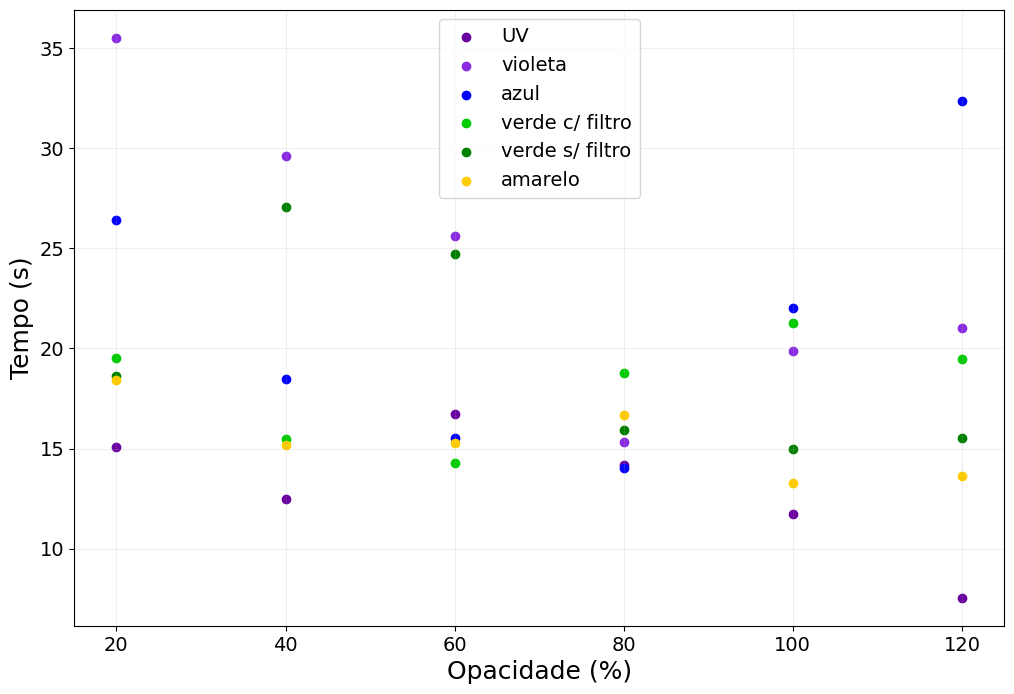

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

# --------------------------- UV ---------------------------
df_UV = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/UV.csv")
df_medias_UV = df_UV.groupby("opacidade", as_index=False).agg(
    media_tensao=("tensao V", "mean"),
    media_tempo=("tempo s", "mean")
)
plt.scatter(df_medias_UV["opacidade"], df_medias_UV["media_tempo"],
            color="#6b00a0", label="UV")

# --------------------------- Violeta ---------------------------
df_violeta = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/violeta.csv")
df_medias_violeta = df_violeta.groupby("opacidade", as_index=False).agg(
    media_tensao=("tensao V", "mean"),
    media_tempo=("tempo s", "mean")
)
plt.scatter(df_medias_violeta["opacidade"], df_medias_violeta["media_tempo"],
            color="#8a2be2", label="violeta")

# --------------------------- Azul ---------------------------
df_azul = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/azul.csv")
df_medias_azul = df_azul.groupby("opacidade", as_index=False).agg(
    media_tensao=("tensao V", "mean"),
    media_tempo=("tempo s", "mean")
)
plt.scatter(df_medias_azul["opacidade"], df_medias_azul["media_tempo"],
            color="#0000ff", label="azul")

# --------------------------- Verde com filtro ---------------------------
df_verdef = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/verde c  filtro.csv")
df_medias_verdef = df_verdef.groupby("opacidade", as_index=False).agg(
    media_tensao=("tensao V", "mean"),
    media_tempo=("tempo s", "mean")
)
plt.scatter(df_medias_verdef["opacidade"], df_medias_verdef["media_tempo"],
            color="#00cc00", label="verde c/ filtro")

# --------------------------- Verde sem filtro ---------------------------
df_verde = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/verde s  filtro.csv")
plt.scatter(df_verde["opacidade"], df_verde["tempo s"],
            color="green", label="verde s/ filtro")

# --------------------------- Amarelo com filtro ---------------------------
df_amarelof = pd.read_csv("/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/amarelo c  filtro .csv")
df_medias_amarelof = df_amarelof.groupby("opacidade", as_index=False).agg(
    media_tensao=("tensao V", "mean"),
    media_tempo=("tempo s", "mean")
)
plt.scatter(df_medias_amarelof["opacidade"], df_medias_amarelof["media_tempo"],
            color="#ffcc00", label="amarelo")

# --------------------------- Estilo do gráfico ---------------------------
plt.xlabel("Opacidade (%)", fontsize=18)
plt.ylabel("Tempo (s)", fontsize=18)

plt.grid(alpha=0.2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)

plt.show()


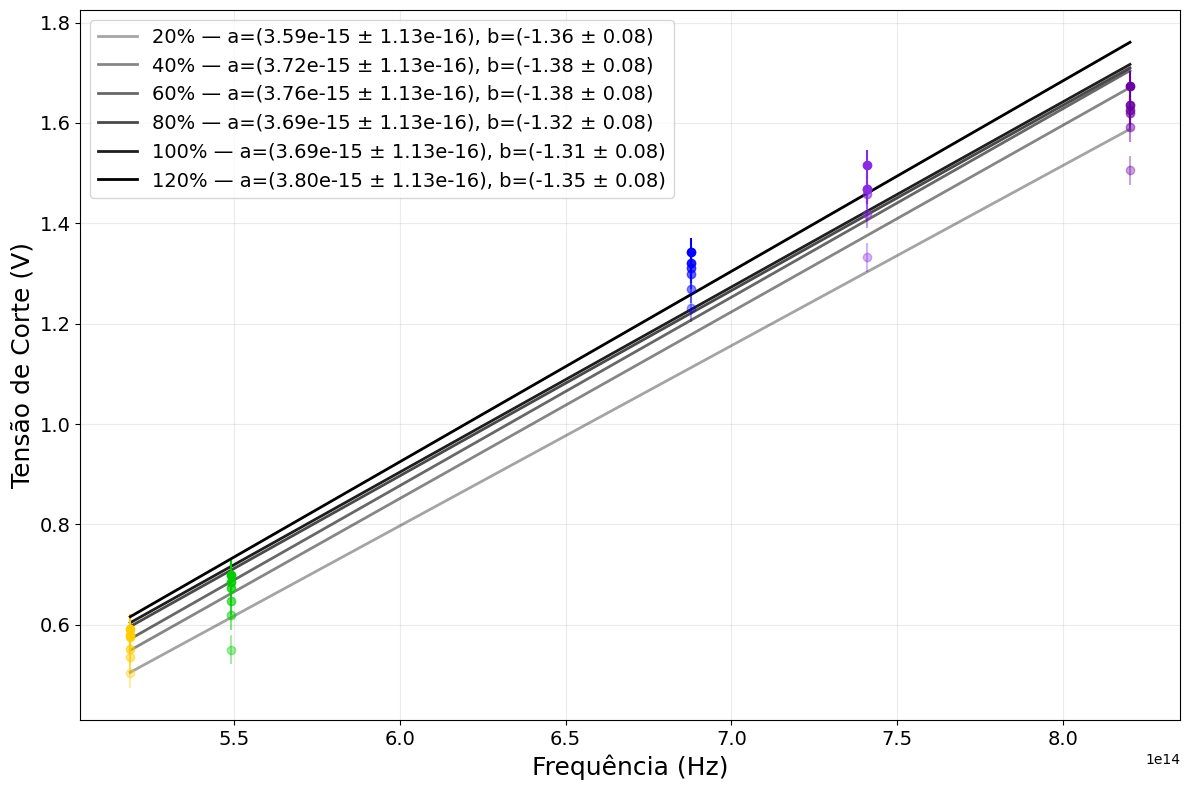

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Frequências das 5 cores ---
Frequencias = np.array([8.20264e14, 7.40858e14, 6.87858e14, 5.48996e14, 5.18672e14])

# --- Séries completas ---
series = [
    df_medias_UV["media_tensao"],
    df_medias_violeta["media_tensao"],
    df_medias_azul["media_tensao"],
    df_medias_verdef["media_tensao"],
    df_medias_amarelof["media_tensao"]
]

# cores das frequências
cores_plot = ["#6b00a0", "#8a2be2", "#0000ff", "#00cc00", "#ffcc00"]

# intensidades e índices
intensidades_txt = ["20%", "40%", "60%", "80%", "100%", "120%"]
intensidades_val = np.array([0.1, 0.3, 0.5, 0.7, 1.0, 1.20])
indices = [0, 1, 2, 3, 4, 5]

# --- Incerteza ---
sigmaV = 0.02886751346

# modelo linear
def linha(f, a, b):
    return a * f + b

plt.figure(figsize=(12,8))

# ============================================
#     AJUSTE PARA CADA INTENSIDADE
# ============================================
for idx, Irel, intensidade_txt in zip(indices, intensidades_val, intensidades_txt):

    tensoes = []
    for serie in series:
        try:
            tensoes.append(serie[idx])
        except:
            tensoes.append(np.nan)

    tensoes = np.array(tensoes)

    mask = ~np.isnan(tensoes)
    f_validos = Frequencias[mask]
    V_validos = tensoes[mask]

    erros = np.ones_like(V_validos) * sigmaV

    # Alpha proporcional à intensidade
    alpha_val = 0.3 + 0.7 * (Irel / 1.2)

    # ---- pontos
    for f, V, cor_ponto in zip(Frequencias, tensoes, cores_plot):
        if not np.isnan(V):
            plt.errorbar(
                f, V, yerr=sigmaV, fmt='o',
                color=cor_ponto, markersize=6,
                alpha=alpha_val
            )

    # ---- ajuste
    params, cov = curve_fit(linha, f_validos, V_validos,
                            sigma=erros, absolute_sigma=True)
    a, b = params
    da, db = np.sqrt(np.diag(cov))

    # === rótulo incluindo incerteza de b ===
    label_reta = (
        f"{intensidade_txt} — "
        f"a=({a:.2e} ± {da:.2e}), "
        f"b=({b:.2f} ± {db:.2f})"
    )

    # ---- reta preta com mesmo alpha
    f_linha = np.linspace(Frequencias.min(), Frequencias.max(), 300)
    plt.plot(
        f_linha, linha(f_linha, a, b),
        color="black", linewidth=2,
        alpha=alpha_val,
        label=label_reta
    )

# ============================================

plt.xlabel("Frequência (Hz)", fontsize=18)
plt.ylabel("Tensão de Corte (V)", fontsize=18)
plt.grid(True, alpha=0.25)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()


===== RESULTADOS =====
Inclinação a (h/e) = 3.7714e-15 ± 1.1236e-16 V·s
Intercepto b = -1.3376e+00 ± 7.5671e-02 V

--- Constante de Planck ---
h_exp = 6.0424e-34 ± 1.8002e-35 J·s
h_real = 6.6261e-34 J·s
Erro relativo de h = 8.81%

--- Razão h/e ---
(h/e)_exp = 3.7714e-15 ± 1.1236e-16 V·s
(h/e)_real = 4.1357e-15 V·s
Erro relativo de h/e = 8.81%


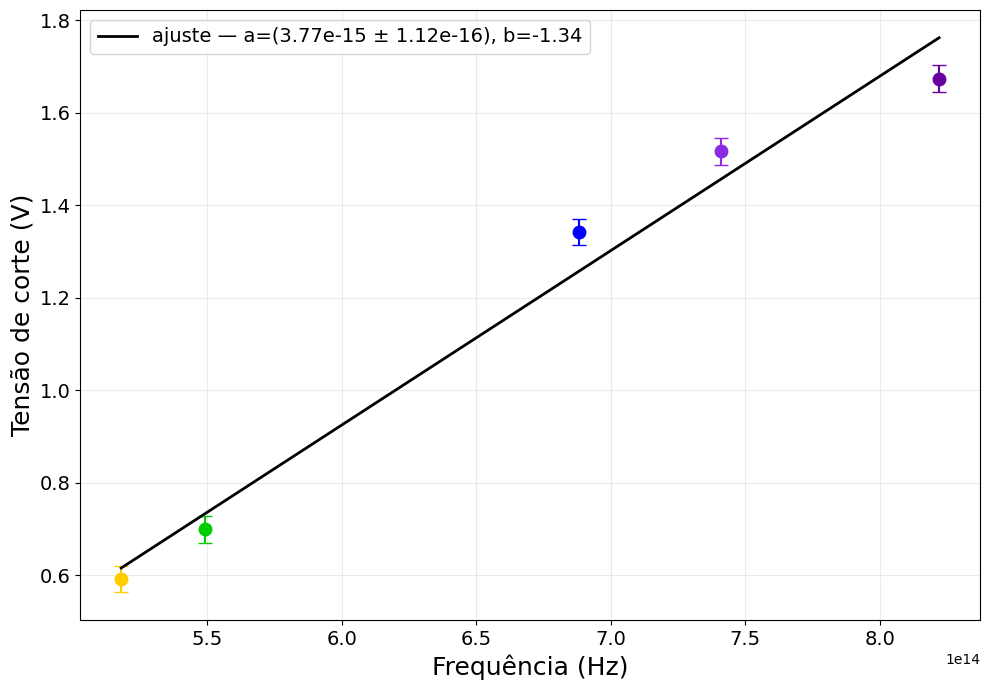

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Dados ---
Frequencias = np.array([8.20264e14, 7.40858e14, 6.87858e14, 5.48996e14, 5.18672e14])

V100 = np.array([
    df_medias_UV["media_tensao"][5],
    df_medias_violeta["media_tensao"][5],
    df_medias_azul["media_tensao"][5],
    df_medias_verdef["media_tensao"][5],
    df_medias_amarelof["media_tensao"][5]
])

# --- Cores reais do espectro ---
cores_plot = [
    "#6b00a0",  # UV
    "#8a2be2",  # violeta
    "#0000ff",  # azul
    "#00cc00",  # verde
    "#ffcc00"   # amarelo
]

# --- Incerteza ---
sigmaV = 0.02886751346
errors = np.ones_like(V100) * sigmaV

# --- Modelo linear ---
def linha(f, a, b):
    return a * f + b

# Ajuste ponderado
params, cov = curve_fit(linha, Frequências, V100, sigma=errors, absolute_sigma=True)
a, b = params
da, db = np.sqrt(np.diag(cov))

# --- Constante de Planck experimental ---
e = 1.602176634e-19
h_exp = a * e
dh_exp = da * e

# --- h/e experimental ---
he_exp = a
dhe_exp = da

# --- Valores reais ---
h_real = 6.62607015e-34
he_real = 4.1356677e-15

# --- Erros relativos ---
erro_rel_h = abs((h_exp - h_real) / h_real) * 100
erro_rel_he = abs((he_exp - he_real) / he_real) * 100

print("===== RESULTADOS =====")
print(f"Inclinação a (h/e) = {a:.4e} ± {da:.4e} V·s")
print(f"Intercepto b = {b:.4e} ± {db:.4e} V")

print("\n--- Constante de Planck ---")
print(f"h_exp = {h_exp:.4e} ± {dh_exp:.4e} J·s")
print(f"h_real = {h_real:.4e} J·s")
print(f"Erro relativo de h = {erro_rel_h:.2f}%")

print("\n--- Razão h/e ---")
print(f"(h/e)_exp = {he_exp:.4e} ± {dhe_exp:.4e} V·s")
print(f"(h/e)_real = {he_real:.4e} V·s")
print(f"Erro relativo de h/e = {erro_rel_he:.2f}%")

# ---------------- Gráfico (estilo padronizado) ----------------
plt.figure(figsize=(10, 7))

alpha_val = 1.0  # uma única intensidade → alpha máximo

# Pontos coloridos
for f, V, cor in zip(Frequências, V100, cores_plot):
    plt.errorbar(
        f, V, yerr=sigmaV, fmt='o',
        color=cor, markersize=9,
        capsize=5, alpha=alpha_val
    )

# Reta preta com estilo do gráfico anterior
f_linha = np.linspace(Frequências.min(), Frequências.max(), 400)
plt.plot(
    f_linha, linha(f_linha, a, b),
    color="black", linewidth=2,
    alpha=alpha_val,
    label=f"ajuste — a=({a:.2e} ± {da:.2e}), b={b:.2f}"
)

plt.xlabel("Frequência (Hz)", fontsize=18)
plt.ylabel("Tensão de corte (V)", fontsize=18)
plt.grid(True, alpha=0.25)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()


===== RESULTADOS (SEM FILTRO) =====
Inclinação a (h/e) = 2.3314e-15 ± 1.1236e-16 V·s
Intercepto b = -2.3650e-01 ± 7.5671e-02 V

--- Constante de Planck ---
h_exp = 3.7353e-34 ± 1.8002e-35 J·s
h_real = 6.6261e-34 J·s
Erro relativo de h = 43.63%

--- Razão h/e ---
(h/e)_exp = 2.3314e-15 ± 1.1236e-16 V·s
(h/e)_real = 4.1357e-15 V·s
Erro relativo de h/e = 43.63%


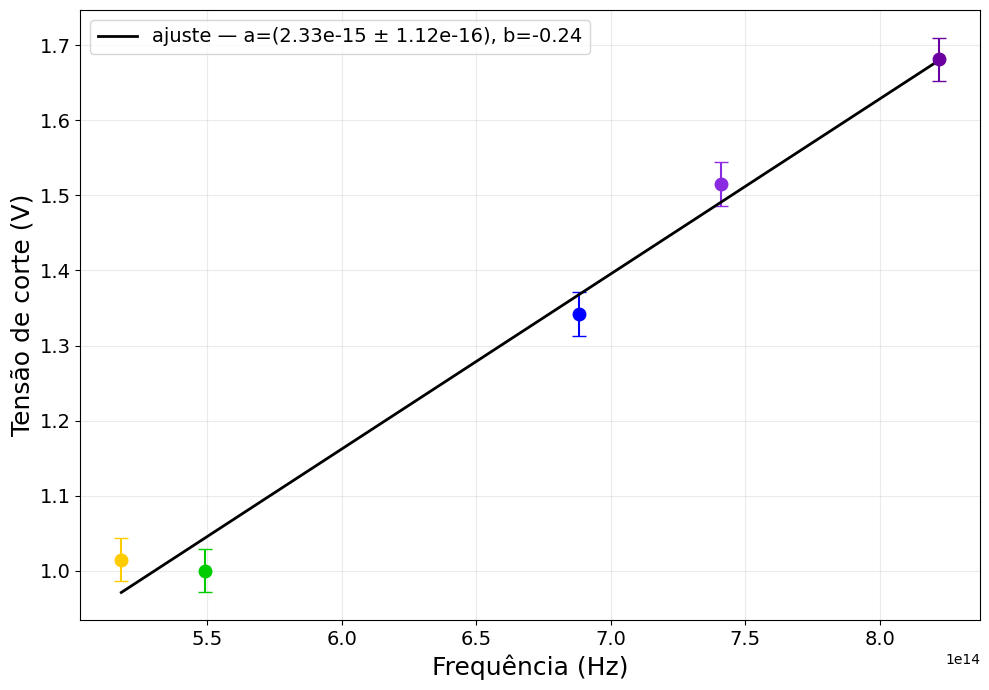

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Dados ---
Frequencias = np.array([8.20264e14, 7.40858e14, 6.87858e14, 5.48996e14, 5.18672e14])


V100 = np.array([
    df_UV["tensao V"][1],
    df_violeta["tensao V"][1],
    df_azul["tensao V"][1],
    df_verde["tensao V"][1],
    1.015  # Amarelo
])

# --- Cores reais do espectro ---
cores_plot = [
    "#6b00a0",  # UV
    "#8a2be2",  # violeta
    "#0000ff",  # azul
    "#00cc00",  # verde
    "#ffcc00"   # amarelo
]

# --- Incerteza ---
sigmaV = 0.02886751346
errors = np.ones_like(V100) * sigmaV

# --- Modelo linear ---
def linha(f, a, b):
    return a*f + b

# Ajuste ponderado (SciPy)
params, cov = curve_fit(linha, Frequências, V100, sigma=errors, absolute_sigma=True)
a, b = params
da, db = np.sqrt(np.diag(cov))

# --- Constante de Planck experimental ---
e = 1.602176634e-19
h_exp = a * e
dh_exp = da * e

# --- h/e experimental ---
he_exp = a
dhe_exp = da

# --- Valores reais ---
h_real = 6.62607015e-34
he_real = 4.1356677e-15

# --- Erros relativos ---
erro_rel_h = abs((h_exp - h_real) / h_real) * 100
erro_rel_he = abs((he_exp - he_real) / he_real) * 100

print("===== RESULTADOS (SEM FILTRO) =====")
print(f"Inclinação a (h/e) = {a:.4e} ± {da:.4e} V·s")
print(f"Intercepto b = {b:.4e} ± {db:.4e} V")

print("\n--- Constante de Planck ---")
print(f"h_exp = {h_exp:.4e} ± {dh_exp:.4e} J·s")
print(f"h_real = {h_real:.4e} J·s")
print(f"Erro relativo de h = {erro_rel_h:.2f}%")

print("\n--- Razão h/e ---")
print(f"(h/e)_exp = {he_exp:.4e} ± {dhe_exp:.4e} V·s")
print(f"(h/e)_real = {he_real:.4e} V·s")
print(f"Erro relativo de h/e = {erro_rel_he:.2f}%")

# ---------------- Gráfico (estilo igual ao anterior) ----------------
plt.figure(figsize=(10, 7))

alpha_val = 1.0  # única intensidade → alpha máximo

# Pontos individuais com suas cores
for f, V, cor in zip(Frequências, V100, cores_plot):
    plt.errorbar(
        f, V, yerr=sigmaV, fmt='o',
        color=cor, markersize=9,
        capsize=5, alpha=alpha_val
    )

# Reta ajustada
f_linha = np.linspace(Frequências.min(), Frequências.max(), 400)
plt.plot(
    f_linha, linha(f_linha, a, b),
    color="black", linewidth=2,
    alpha=alpha_val,
    label=f"ajuste — a=({a:.2e} ± {da:.2e}), b={b:.2f}"
)

plt.xlabel("Frequência (Hz)", fontsize=18)
plt.ylabel("Tensão de corte (V)", fontsize=18)
plt.grid(True, alpha=0.25)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()


Text(0, 0.5, 'opacidade %')

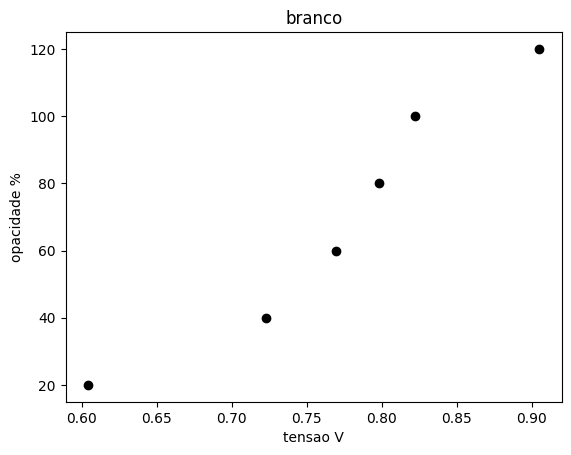

In [ ]:
url_branco="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/branco.csv"
df_branco = pd.read_csv(url_branco)
df_medias_branco = df_branco.groupby("opacidade", as_index=False).agg(
    media_tensao=("tensao V", "mean"),
    media_tempo=("tempo s", "mean")
)


plt.scatter(df_medias_branco["media_tensao"],df_medias_branco["opacidade"],color="black")
plt.title("branco")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")

Text(0, 0.5, 'opacidade %')

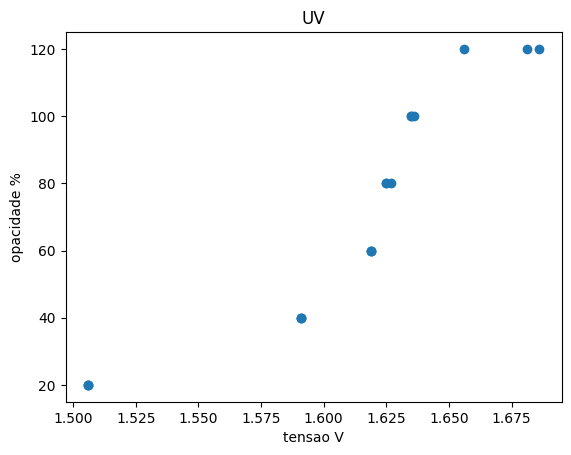

In [ ]:
url_UV="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/UV.csv"
df_UV = pd.read_csv(url_UV)
plt.scatter(df_UV["tensao V"],df_UV["opacidade"])
plt.title("UV")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")

Text(0, 0.5, 'opacidade %')

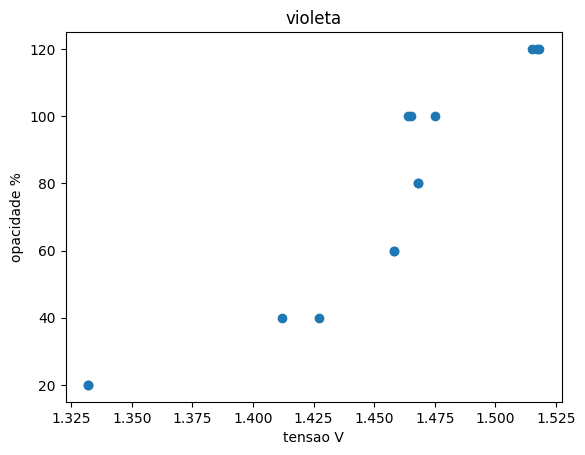

In [ ]:
url_violeta="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/violeta.csv"
df_violeta = pd.read_csv(url_violeta)
plt.scatter(df_violeta["tensao V"],df_violeta["opacidade"])
plt.title("violeta")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")

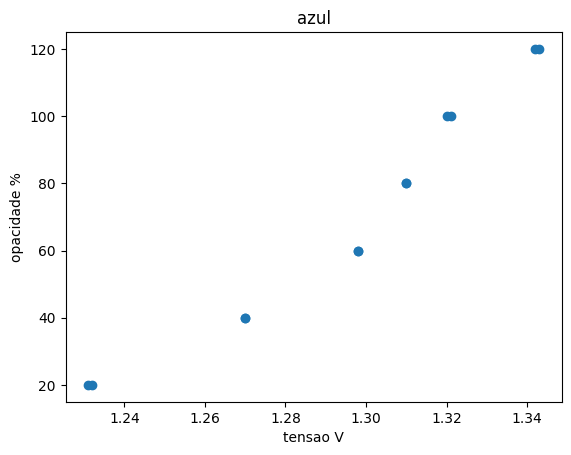

In [ ]:
url_azul="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/azul.csv"
df_azul = pd.read_csv(url_azul)
plt.scatter(df_azul["tensao V"],df_azul["opacidade"])
plt.title("azul")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")
plt.show()


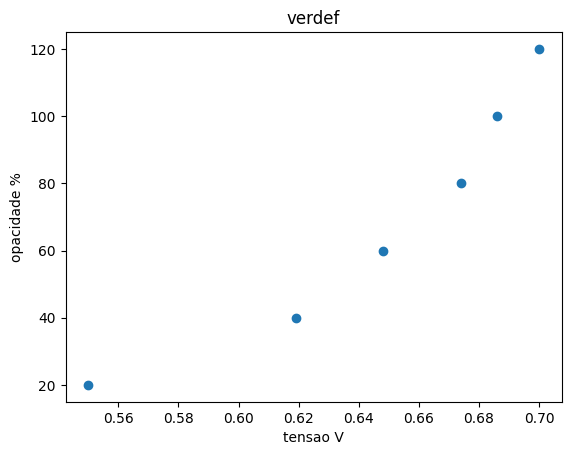

In [ ]:
url_verdef="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/verde c  filtro.csv"
df_verdef = pd.read_csv(url_verdef)
plt.scatter(df_verdef["tensao V"],df_verdef["opacidade"])
plt.title("verdef")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")
plt.show()


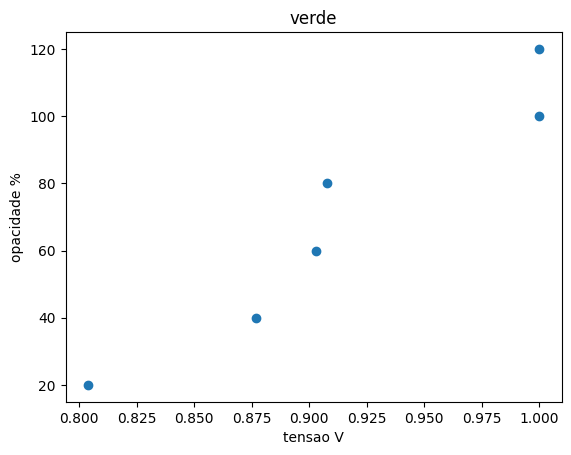

In [ ]:
url_verde="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/verde s  filtro.csv"
df_verde = pd.read_csv(url_verde)
plt.scatter(df_verde["tensao V"],df_verde["opacidade"])
plt.title("verde")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")
plt.show()


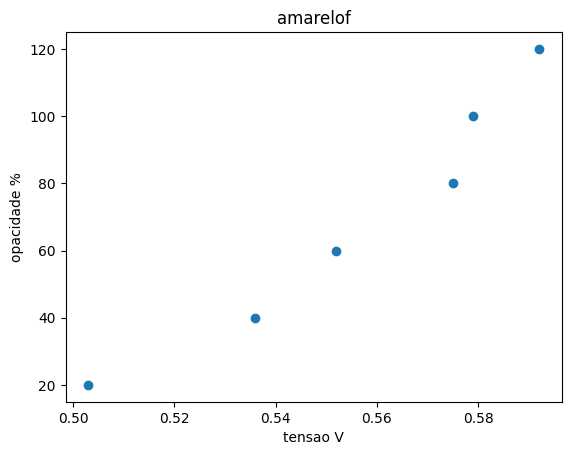

In [ ]:
url_amarelof="/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt1/amarelo c  filtro .csv"
df_amarelof = pd.read_csv(url_amarelof)
plt.scatter(df_amarelof["tensao V"],df_amarelof["opacidade"])
plt.title("amarelof")
plt.xlabel("tensao V")
plt.ylabel("opacidade %")
plt.show()


ValueError: The number of FixedLocator locations (5), usually from a call to set_ticks, does not match the number of labels (6).

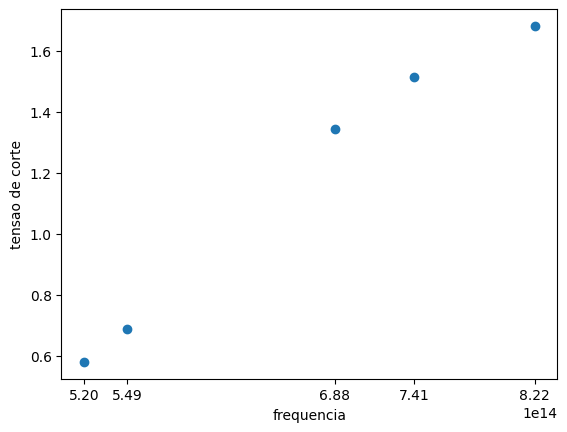

In [ ]:
cores = np.array([
    "UV_365nm",
    "violeta_404nm", "azul_435nm",
    "verde_546nm", "amarelo_577nm", "amarelo_579nm"
])
Frequências = np.array([ 8.22e+14, 7.41e+14, 6.88e+14, 5.49e+14, 5.20e+14])


V100=np.array([df_UV["tensao V"][1],df_violeta["tensao V"][1],df_azul["tensao V"][1],df_verdef["tensao V"][1],df_amarelof["tensao V"][1]])
plt.scatter(Frequências,V100)
plt.xlabel("frequencia")
plt.ylabel("tensao de corte")
plt.xticks(Frequências,cores)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Dados ---
Frequências = np.array([8.22e14, 7.41e14, 6.88e14, 5.49e14, 5.20e14])

V100 = np.array([
    df_UV["tensao V"][1],
    df_violeta["tensao V"][1],
    df_azul["tensao V"][1],
    df_verdef["tensao V"][1],
    df_amarelof["tensao V"][1]
])

cores = np.array(["UV_365nm","violeta_404nm","azul_435nm","verde_546nm","amarelo_577nm"])

# --- Incerteza da tensão ---
sigmaV = 0.02886751346
errors = np.ones_like(V100) * sigmaV

# --- Modelo linear ---
def linha(f, a, b):
    return a*f + b

# Ajuste ponderado
params, cov = curve_fit(linha, Frequências, V100, sigma=errors, absolute_sigma=True)

a, b = params               # coeficientes
da, db = np.sqrt(np.diag(cov))  # incertezas

# --- Constante de Planck ---
e = 1.602176634e-19
h_exp = a * e
dh_exp = da * e

print(f"Inclinação a = {a:.4e} ± {da:.4e}   (h/e)")
print(f"Intercepto b = {b:.4e} ± {db:.4e}")
print(f"h_exp = {h_exp:.4e} ± {dh_exp:.4e} J·s")
print("h_tabelado = 6.62607015e-34 J·s")
